In [27]:
from pathlib import Path
from PIL import Image, ImageDraw
from matplotlib.patches import Rectangle

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# [수정 변수] 데이터 폴더
DATA_DIR = Path("origin")

# DATA_DIR 폴더에서 BMP 파일 검색
origin_files = sorted(DATA_DIR.rglob("*.bmp"))

print("검색된 이미지:", len(origin_files))

for i, path in enumerate(origin_files[:10]):
    print(i, path.name)

if not origin_files:
    raise FileNotFoundError(
        "Origin BMP 파일을 찾지 못했습니다."
    )

# [수정 변수] 사용할 이미지
SOURCE_FILE = origin_files[11]

with Image.open(SOURCE_FILE) as img:
    original = img.convert("RGB")

gray_image = original.convert("L")
gray = np.array(gray_image)

h, w = gray.shape

print("파일명:", SOURCE_FILE.name)
print("이미지 크기:", original.size)
print("원본 모드:", original.mode)
print("Grayscale:", gray.shape)
print("자료형:", gray.dtype)
print("픽셀 최솟값:", gray.min())
print("픽셀 최댓값:", gray.max())

검색된 이미지: 119
0 Wafer12_10_Origin.bmp
1 Wafer12_11_Origin.bmp
2 Wafer12_12_Origin.bmp
3 Wafer12_13_Origin.bmp
4 Wafer12_14_Origin.bmp
5 Wafer12_15_Origin.bmp
6 Wafer12_1_Origin.bmp
7 Wafer12_2_Origin.bmp
8 Wafer12_3_Origin.bmp
9 Wafer12_4_Origin.bmp
파일명: Wafer12_6_Origin.bmp
이미지 크기: (5120, 5120)
원본 모드: RGB
Grayscale: (5120, 5120)
자료형: uint8
픽셀 최솟값: 0
픽셀 최댓값: 237


In [28]:
def show_images(images, titles, columns=3):

    n = len(images)
    rows = int(np.ceil(n / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(5 * columns, 4.5 * rows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, image, title in zip(
        axes.flat, images, titles
    ):
        if isinstance(image, Image.Image):
            image = np.array(image)

        if image.ndim == 2:
            ax.imshow(
                image,
                cmap="gray",
                vmin=0,
                vmax=255
            )
        else:
            ax.imshow(image)

        ax.set_title(title)

    plt.tight_layout()
    plt.show()

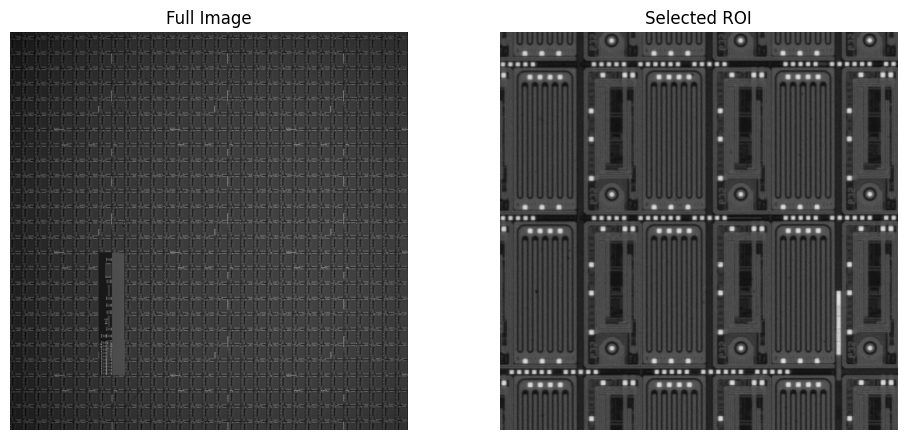

In [29]:
# [수정 변수] ROI 시작 위치
left, top = 2200, 2200

# [수정 변수] ROI 크기
cropsize_x = 512
cropsize_y = 512

# ROI 경계 좌표
box_e = (
    left,
    top,
    left + cropsize_x,
    top + cropsize_y
)

# Pillow의 crop() 사용
roi_image = gray_image.crop(box_e)
roi = np.array(roi_image)

show_images(
    [gray, roi],
    ["Full Image", "Selected ROI"],
    columns=2
)

원본: (5120, 5120)
Resize: (256, 256)
ROI: (256, 256)


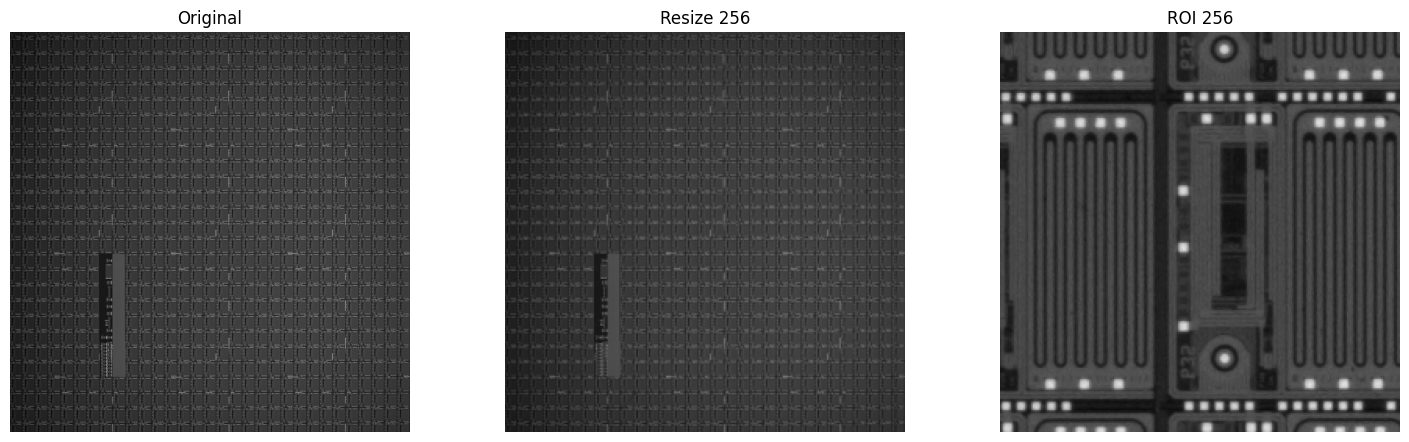

In [30]:
# [수정 변수] 결과 크기
target_size = 256

# 1. 원본 전체 Resize
resized = cv2.resize(
    gray,
    (target_size, target_size),
    interpolation=cv2.INTER_AREA
)

# 2. 원본 일부 ROI 추출
# [수정 변수] ROI 시작 위치
left, top = 2200, 2200

box_e = (
    left,
    top,
    left + target_size,
    top + target_size
)

roi_image = gray_image.crop(box_e)
roi = np.array(roi_image)

print("원본:", gray.shape)
print("Resize:", resized.shape)
print("ROI:", roi.shape)

# 3. 결과 비교
show_images(
    [gray, resized, roi],
    ["Original", "Resize 256", "ROI 256"]
)

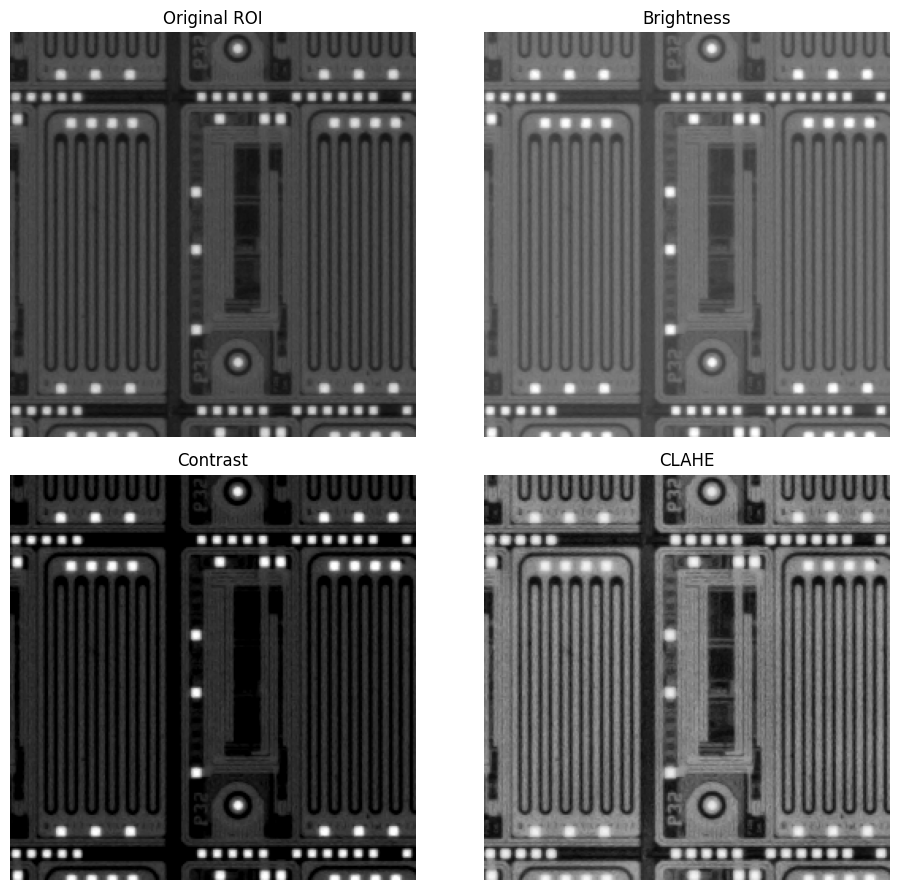

In [31]:
# [수정 변수] 전처리 매개변수
brightness_offset = 40
contrast_factor = 1.5
clip_limit = 2.0
tile_grid_size = (8, 8)

# 계산용 배열
arr = roi.astype(np.float32)

# 1. 밝기 조절
bright = np.clip(
    arr + brightness_offset,
    0,
    255
).astype(np.uint8)

# 2. 대비 조절
contrast = np.clip(
    (arr - 128) * contrast_factor + 128,
    0,
    255
).astype(np.uint8)

# 3. CLAHE
clahe = cv2.createCLAHE(
    clipLimit=clip_limit,
    tileGridSize=tile_grid_size
)

clahe_img = clahe.apply(roi)

# 4. 결과 비교
show_images(
    [roi, bright, contrast, clahe_img],
    [
        "Original ROI",
        "Brightness",
        "Contrast",
        "CLAHE"
    ],
    columns=2
)

In [32]:
def split_patches(img, patch_size=512, stride=None):

    # stride 미지정 시 겹치지 않도록 설정
    if stride is None:
        stride = patch_size

    if patch_size <= 0 or stride <= 0:
        raise ValueError(
            "patch_size와 stride는 양수여야 합니다."
        )

    # 이미지 높이와 너비
    h, w = img.shape[:2]

    patches = []

    # 세로 방향 이동
    for y in range(
        0, h - patch_size + 1, stride
    ):

        # 가로 방향 이동
        for x in range(
            0, w - patch_size + 1, stride
        ):

            # 현재 좌표에서 패치 추출
            patch = img[
                y:y + patch_size,
                x:x + patch_size
            ]

            # 좌표와 패치 이미지 기록
            patches.append({
                "x": x,
                "y": y,
                "patch": patch
            })

    return patches

256x256: 400개
512x512: 100개
1024x1024: 25개


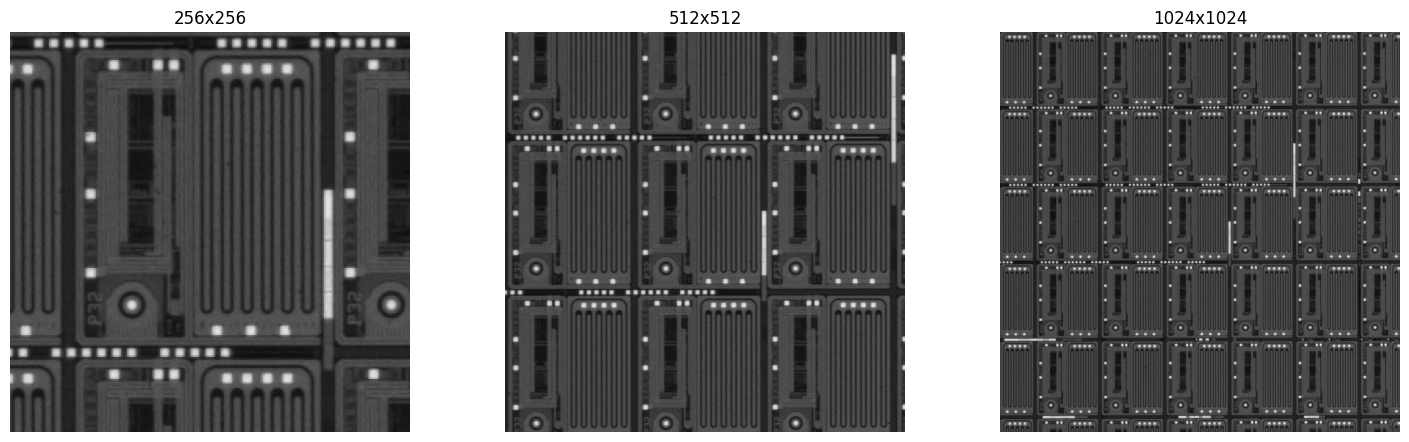

In [33]:
# [수정 변수] 비교할 패치 크기
patch_sizes = [256, 512, 1024]

# 원본 중심 좌표
h, w = gray.shape
center_x = w // 2
center_y = h // 2

sample_patches = []

for size in patch_sizes:

    # 겹치지 않는 패치 개수 계산
    count_x = (w - size) // size + 1
    count_y = (h - size) // size + 1

    print(
        f"{size}x{size}: "
        f"{count_x * count_y}개"
    )

    # 같은 중심 위치에서 패치 추출
    left = center_x - size // 2
    top = center_y - size // 2

    box = (
        left,
        top,
        left + size,
        top + size
    )

    patch = gray_image.crop(box)
    sample_patches.append(patch)

# 패치 크기별 이미지 비교
show_images(
    sample_patches,
    [f"{size}x{size}" for size in patch_sizes]
)

In [34]:
patch_size = 512

# [수정 변수] Stride 목록
strides = [512, 400, 256]

for stride in strides:

    count_x = (
        (w - patch_size) // stride + 1
    )
    count_y = (
        (h - patch_size) // stride + 1
    )

    print(
        f"Stride {stride}: "
        f"{count_x * count_y}개"
    )

Stride 512: 100개
Stride 400: 144개
Stride 256: 361개


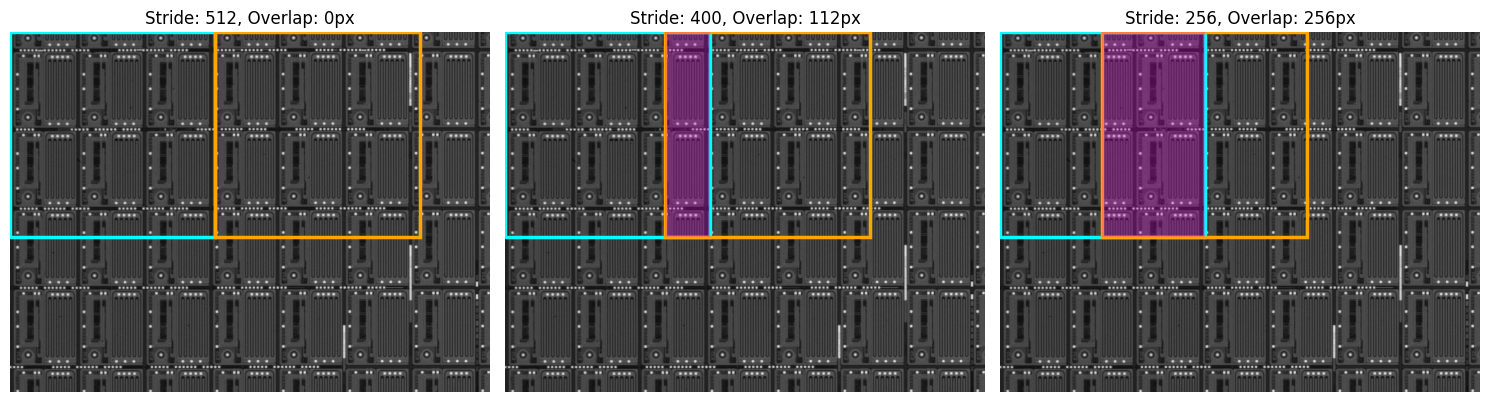

In [35]:
patch_size = 512
strides = [512, 400, 256]

# [수정 변수] 관찰 영역
left, top = 1800, 1800
cropsize_x, cropsize_y = 1200, 900

box = (
    left,
    top,
    left + cropsize_x,
    top + cropsize_y
)

region = gray_image.crop(box)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5)
)

for ax, stride in zip(axes, strides):

    ax.imshow(
        region,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    # 첫 번째 패치
    ax.add_patch(Rectangle(
        (0, 0),
        patch_size,
        patch_size,
        fill=False,
        edgecolor="cyan",
        linewidth=2.5
    ))

    # 두 번째 패치
    ax.add_patch(Rectangle(
        (stride, 0),
        patch_size,
        patch_size,
        fill=False,
        edgecolor="orange",
        linewidth=2.5
    ))

    # 겹치는 영역
    overlap = max(0, patch_size - stride)

    if overlap > 0:
        ax.add_patch(Rectangle(
            (stride, 0),
            overlap,
            patch_size,
            facecolor="magenta",
            alpha=0.25,
            linewidth=0
        ))

    ax.set_title(
        f"Stride: {stride}, "
        f"Overlap: {overlap}px"
    )

    ax.set_xlim(0, cropsize_x)
    ax.set_ylim(cropsize_y, 0)
    ax.axis("off")

plt.tight_layout()
plt.show()

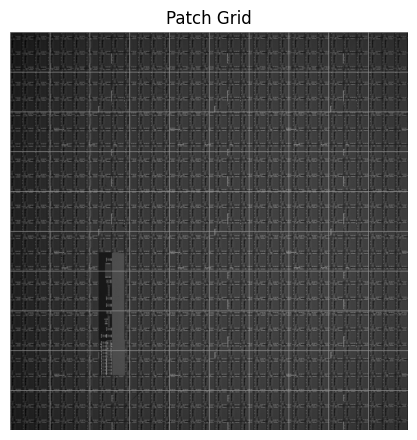

In [36]:
# [수정 변수] 패치 설정
patch_size = 512
stride = 512

# 미리보기 이미지
preview_size = 640

preview = gray_image.resize(
    (preview_size, preview_size)
).copy()

draw = ImageDraw.Draw(preview)

scale_x = preview_size / w
scale_y = preview_size / h

for y in range(
    0, h - patch_size + 1, stride
):
    for x in range(
        0, w - patch_size + 1, stride
    ):

        x1 = round(x * scale_x)
        y1 = round(y * scale_y)

        x2 = round(
            (x + patch_size) * scale_x
        )
        y2 = round(
            (y + patch_size) * scale_y
        )

        draw.rectangle(
            (x1, y1, x2, y2),
            outline="lime",
            width=1
        )

show_images(
    [preview],
    ["Patch Grid"],
    columns=1
)

In [37]:
# [수정 변수] 패치 설정
patch_size = 512
stride = 512

# [수정 변수] 저장 폴더
OUTPUT_DIR = Path("output_patches")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# 패치 생성
patches = split_patches(
    gray,
    patch_size=patch_size,
    stride=stride
)

metadata = []

# 패치 이미지 저장
for idx, item in enumerate(patches):

    patch = item["patch"]
    x = item["x"]
    y = item["y"]

    filename = (
        f"{SOURCE_FILE.stem}_"
        f"patch_{idx:03d}.png"
    )

    save_path = OUTPUT_DIR / filename

    Image.fromarray(patch).save(save_path)

    metadata.append({
        "filename": filename,
        "source": SOURCE_FILE.name,
        "x": x,
        "y": y,
        "patch_size": patch_size,
        "stride": stride
    })

# 메타데이터 표와 CSV 저장
metadata_df = pd.DataFrame(metadata)

metadata_path = OUTPUT_DIR / "metadata.csv"

metadata_df.to_csv(
    metadata_path,
    index=False,
    encoding="utf-8-sig"
)

print("패치 개수:", len(patches))
print("저장 폴더:", OUTPUT_DIR)
print("메타데이터:", metadata_path)

print(metadata_df.head())

패치 개수: 100
저장 폴더: output_patches
메타데이터: output_patches\metadata.csv
                         filename                source     x  y  patch_size  \
0  Wafer12_6_Origin_patch_000.png  Wafer12_6_Origin.bmp     0  0         512   
1  Wafer12_6_Origin_patch_001.png  Wafer12_6_Origin.bmp   512  0         512   
2  Wafer12_6_Origin_patch_002.png  Wafer12_6_Origin.bmp  1024  0         512   
3  Wafer12_6_Origin_patch_003.png  Wafer12_6_Origin.bmp  1536  0         512   
4  Wafer12_6_Origin_patch_004.png  Wafer12_6_Origin.bmp  2048  0         512   

   stride  
0     512  
1     512  
2     512  
3     512  
4     512  


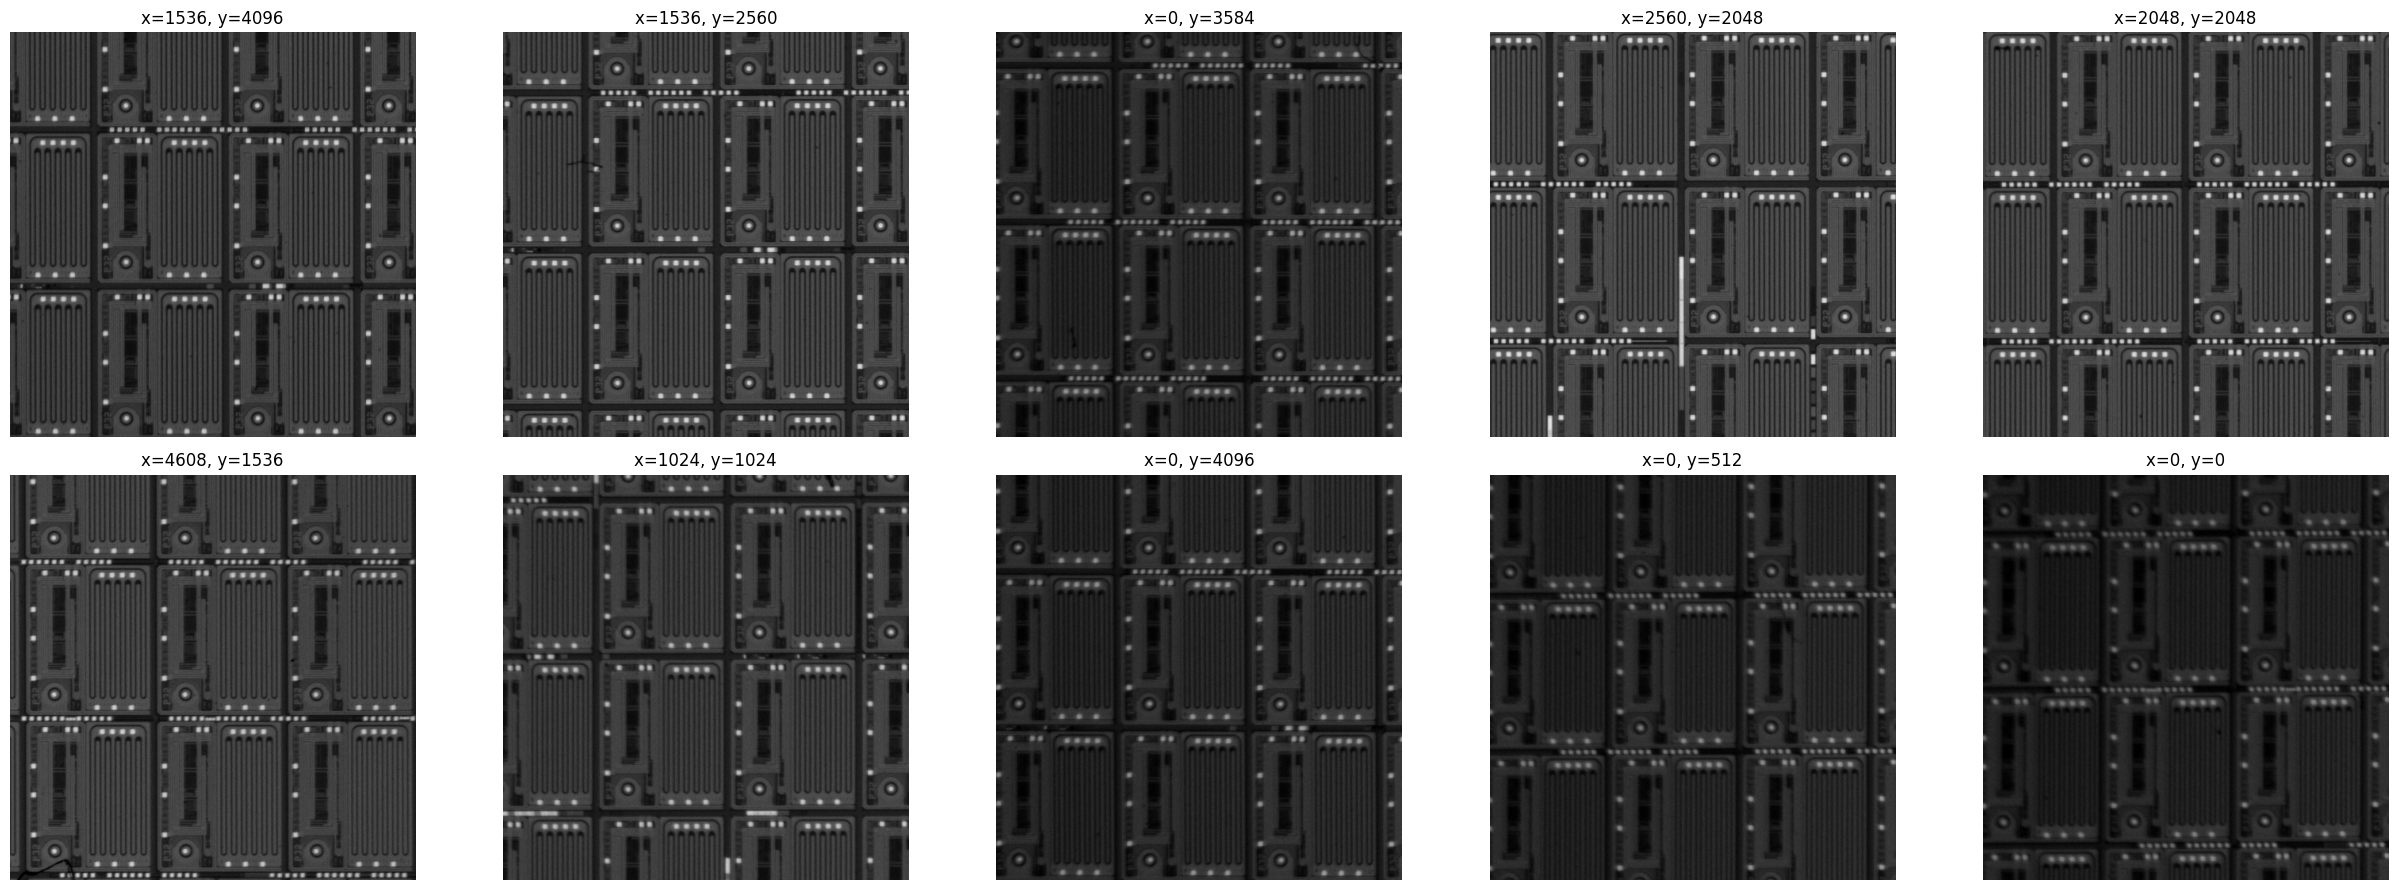

In [38]:
# 무작위로 최대 10개 선택
sample = metadata_df.sample(
    n=min(10, len(metadata_df)),
    random_state=42
)

sample_images = []
sample_titles = []

for _, row in sample.iterrows():

    path = OUTPUT_DIR / row["filename"]

    with Image.open(path) as img:
        sample_images.append(img.copy())

    sample_titles.append(
        f"x={row['x']}, y={row['y']}"
    )

show_images(
    sample_images,
    sample_titles,
    columns=5
)